Best route found:
4 -> 6 -> 7 -> 1 -> 5 -> 0 -> 3 -> 2 -> 4

Best route coordinates:
City 4: [8 5]
City 6: [7 7]
City 7: [3 8]
City 1: [2 6]
City 5: [1 3]
City 0: [0 0]
City 3: [6 1]
City 2: [5 4]
City 4: [8 5]

Shortest distance found: 27.33


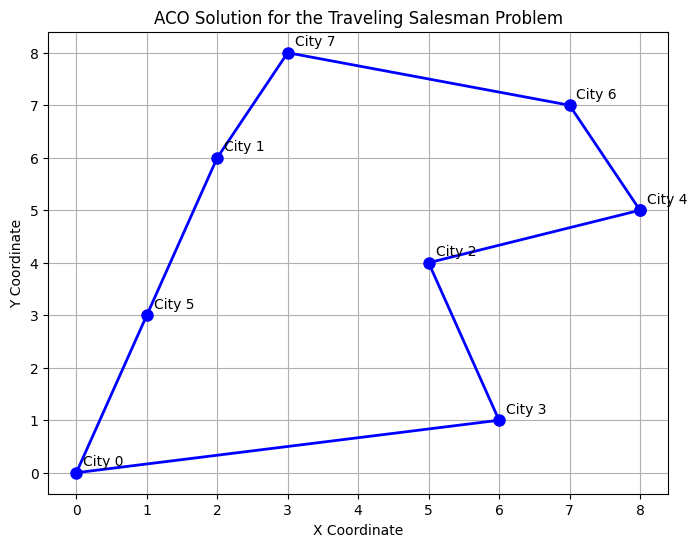

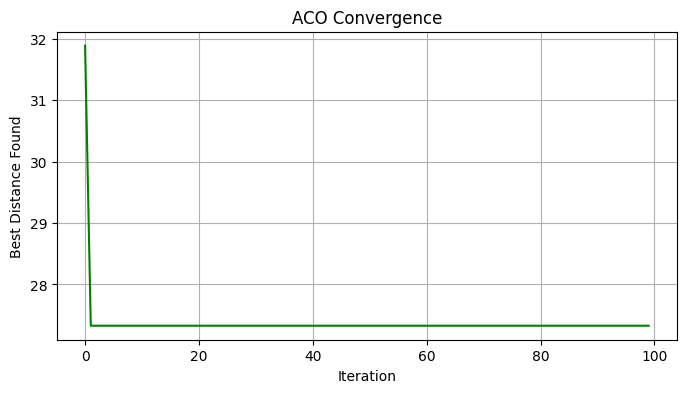

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Define the cities and their coordinates
cities = np.array([
    [0, 0],
    [2, 6],
    [5, 4],
    [6, 1],
    [8, 5],
    [1, 3],
    [7, 7],
    [3, 8]
])

n_cities = len(cities)

# Calculate Euclidean distance between every pair of cities
distance = np.zeros((n_cities, n_cities))

for i in range(n_cities):
    for j in range(n_cities):
        distance[i][j] = np.linalg.norm(cities[i] - cities[j])

# 2. Initialize ACO parameters
n_ants = 10
n_iterations = 100

alpha = 1.0       # Importance of pheromone
beta = 2.0        # Importance of heuristic information
rho = 0.5         # Pheromone evaporation rate
Q = 100           # Pheromone deposit constant

initial_pheromone = 1.0

pheromone = np.ones((n_cities, n_cities)) * initial_pheromone

# Heuristic information: inverse of distance
heuristic = 1 / (distance + 1e-10)
np.fill_diagonal(heuristic, 0)

# Store the best solution
best_route = None
best_distance = float("inf")
convergence = []

# 3. Construct solutions and 4. Update pheromones
for iteration in range(n_iterations):

    ant_routes = []
    ant_distances = []

    for ant in range(n_ants):

        # Choose a random starting city
        start_city = np.random.randint(n_cities)
        route = [start_city]
        unvisited = set(range(n_cities))
        unvisited.remove(start_city)

        # Visit every city exactly once
        while unvisited:
            current_city = route[-1]
            candidates = list(unvisited)

            # Calculate transition probabilities
            probabilities = np.array([
                (pheromone[current_city][city] ** alpha) *
                (heuristic[current_city][city] ** beta)
                for city in candidates
            ])

            probabilities /= probabilities.sum()

            # Select the next city probabilistically
            next_city = np.random.choice(
                candidates, p=probabilities
            )

            route.append(next_city)
            unvisited.remove(next_city)

        # Return to the starting city
        route.append(start_city)

        # Calculate total tour length
        total_distance = sum(
            distance[route[i]][route[i + 1]]
            for i in range(len(route) - 1)
        )

        ant_routes.append(route)
        ant_distances.append(total_distance)

        # Update the global best solution
        if total_distance < best_distance:
            best_distance = total_distance
            best_route = route.copy()

    # Evaporate pheromones
    pheromone *= (1 - rho)

    # Deposit pheromones based on route quality
    for route, tour_length in zip(ant_routes, ant_distances):
        deposit = Q / tour_length

        for i in range(len(route) - 1):
            city_a = route[i]
            city_b = route[i + 1]

            pheromone[city_a][city_b] += deposit
            pheromone[city_b][city_a] += deposit

    convergence.append(best_distance)

# 5. Display the best solution
print("Best route found:")
print(" -> ".join(map(str, best_route)))

print("\nBest route coordinates:")
for city in best_route:
    print(f"City {city}: {cities[city]}")

print(f"\nShortest distance found: {best_distance:.2f}")

# 6. Visualize the best route
plt.figure(figsize=(8, 6))

route_coordinates = cities[best_route]

plt.plot(
    route_coordinates[:, 0],
    route_coordinates[:, 1],
    "o-",
    color="blue",
    linewidth=2,
    markersize=8
)

for i, (x, y) in enumerate(cities):
    plt.annotate(
        f"City {i}",
        (x, y),
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.title("ACO Solution for the Traveling Salesman Problem")
plt.xlabel("X Coordinate")
plt.ylabel("Y Coordinate")
plt.grid(True)
plt.show()

# Plot convergence
plt.figure(figsize=(8, 4))
plt.plot(convergence, color="green")
plt.title("ACO Convergence")
plt.xlabel("Iteration")
plt.ylabel("Best Distance Found")
plt.grid(True)
plt.show()